<a href="https://colab.research.google.com/github/frandresst-wq/Proyecto-de-Ciencia-de-Datos/blob/main/S2_Notebook_Laboratorio_CDD_Soto_Franco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 2 — Calidad y preparación de tu conjunto de datos
**Ciencia de Datos · Semana 2 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA1 (cierre) · RA3 (transversal) |
| **Duración estimada** | 1 h asincrónica + 1 h de trabajo autónomo |
| **Insumo** | El conjunto de datos que elegiste en la semana 1 |
| **Producto** | Conjunto limpio + bitácora completada + avance versionado |
| **Estudiante** | Franco Soto Soto |

---

Este laboratorio **no trae los datos**: los traes tú. Todo lo que hagas aquí es el cuerpo de la **Entrega 1**, que rindes al cierre de esta semana.

Ten abierta en paralelo la planilla `S2_Bitacora_Decisiones_CDD.xlsx`. Escríbela **mientras trabajas**, no al final: reconstruir después por qué tomaste una decisión es mucho más difícil de lo que parece.

In [4]:
import pandas as pd
import numpy as np

RUTA = ''
SEMILLA = 20262
np.random.seed(SEMILLA)

ARCHIVO = 'ipc_base_20237baa955a44fe4eada201c196338fb3be.csv'
SEPARADOR = ';'

# Agregamos encoding='latin1' para evitar el error con caracteres en español
df = pd.read_csv(RUTA + ARCHIVO, sep=SEPARADOR, encoding='latin1')
print('Forma:', df.shape)
df.head(200)

Forma: (20262, 16)


,Año,Mes,División,Grupo,Clase,Subclase,Producto,Glosa,Ponderación,Índice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%),Incidencia 12 Meses (%)
0,2024,1,NaN,NaN,NaN,NaN,NaN,IPC General,NaN,"101,72","0,7","0,7","3,8",NaN,NaN,NaN
1,2024,1,1.0,NaN,NaN,NaN,NaN,ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS,"22,15348","103,26",1,1,NaN,"0,215","0,215",NaN
2,2024,1,1.0,1.0,NaN,NaN,NaN,ALIMENTOS,"19,9127","103,14","0,8","0,8",NaN,"0,158","0,158",NaN
3,2024,1,1.0,1.0,1.0,NaN,NaN,"PAN, CEREALES, HARINAS Y PASTAS","4,29417","102,1",1,1,NaN,"0,045","0,045",NaN
4,2024,1,1.0,1.0,1.0,1.0,NaN,ARROZ,"0,22304","106,3","-0,1","-0,1",NaN,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2024,1,3.0,2.0,1.0,NaN,NaN,CALZADO,"1,01096","97,67",-1,-1,NaN,"-0,01","-0,01",NaN
196,2024,1,3.0,2.0,1.0,1.0,NaN,CALZADO PARA HOMBRES,"0,38681","96,16","-2,8","-2,8",NaN,"-0,011","-0,011",NaN
197,2024,1,3.0,2.0,1.0,1.0,1.0,ZAPATILLAS PARA HOMBRE,"0,27643","97,43","-2,4","-2,4",NaN,"-0,007","-0,007",NaN
198,2024,1,3.0,2.0,1.0,1.0,2.0,ZAPATOS PARA HOMBRE,"0,11038","92,96","-3,8","-3,8",NaN,"-0,004","-0,004",NaN


In [24]:
import pandas as pd
import numpy as np

# Cargamos el DataFrame 'df' para asegurar que esté en memoria
RUTA = ''
ARCHIVO = 'ipc_base_20237baa955a44fe4eada201c196338fb3be.csv'
SEPARADOR = ';'

df = pd.read_csv(RUTA + ARCHIVO, sep=SEPARADOR, encoding='latin1')
print('Datos cargados exitosamente. Estructura del DataFrame:', df.shape)

Datos cargados exitosamente. Estructura del DataFrame: (20262, 16)


In [5]:
df.dtypes

,0
Año,int64
Mes,int64
División,float64
Grupo,float64
Clase,float64
Subclase,float64
Producto,float64
Glosa,object
Ponderación,object
Índice,object


Se evidencia que Ponderación, Indice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%) y Incidencia 12 Meses (%) Aparecen como object.



## Parte 1 · Diagnóstico de las cinco dimensiones

Antes de limpiar nada, hay que saber qué tienes. Completa la hoja **«Resumen de calidad»** de la bitácora con los resultados de esta parte.

++++++++ ¿Cómo evaluar estas dimensiones con Pandas?

1. **Completitud:**
Por ejemplo, df.isna().sum()
Cuenta los valores faltantes de cada columna.

2. **Exactitud:**
Por ejemplo, df.describe().T.round(2)
Permite identificar valores mínimos, máximos y rangos sospechosos en variables numéricas.

3. **Consistencia:**
Por ejemplo, (df['fecha_termino'] < df['fecha_inicio']).sum()
Cuenta los registros cuya fecha de término es anterior a la fecha de inicio, suponiendo que ambas columnas contienen fechas válidas.

4. **Unicidad:**
Por ejemplo, df.duplicated().sum()
Cuenta las filas duplicadas exactas, sin incluir la primera aparición.

5. **Oportunidad:**
Por ejemplo, df['fecha'].max()
Obtiene la fecha más reciente disponible en el conjunto de datos, siempre que la columna tenga un tipo de fecha adecuado.


### 1.1 Completitud

In [6]:
faltantes = df.isna().sum().to_frame('faltantes')
faltantes['pct'] = (faltantes['faltantes'] / len(df) * 100).round(2)
faltantes.sort_values('faltantes', ascending=False)

,faltantes,pct
Producto,10923,53.91
Incidencia 12 Meses (%),7389,36.47
Variación 12 Meses (%),7356,36.30
Subclase,5247,25.90
Clase,1980,9.77
Grupo,462,2.28
División,33,0.16
Ponderación,33,0.16
Incidencia Acumulada (%),33,0.16
Incidencia Mensual (%),33,0.16


### ✏️ Actividad 1.1

Elige la columna con más faltantes y averigua **si se reparten al azar o se concentran en algún grupo**. Usa `pd.crosstab` contra alguna columna categórica, como en el Ejercicio 1 del cuaderno resuelto.

Es la diferencia entre poder imputar y tener que declarar.

In [7]:
# Identificamos la columna con más nulos: 'Producto'
# Evaluamos si su ausencia se concentra según la 'División'
tabla_faltantes_producto = pd.crosstab(
    df['División'].fillna('General / No aplica'),
    df['Producto'].isna(),
    rownames=['División'],
    colnames=['Producto Faltante (NaN)']
)

tabla_faltantes_producto.columns = ['Presente (Tiene Producto)', 'Faltante (Es Categoría Superior)']
tabla_faltantes_producto['% Faltantes'] = (
    tabla_faltantes_producto['Faltante (Es Categoría Superior)'] /
    tabla_faltantes_producto.sum(axis=1) * 100
).round(2)

display(tabla_faltantes_producto)

,Presente (Tiene Producto),Faltante (Es Categoría Superior),% Faltantes
División,,,
1.0,2673,2145,44.52
2.0,198,429,68.42
3.0,759,561,42.50
4.0,495,858,63.41
5.0,1254,1320,51.28
6.0,759,759,50.00
7.0,825,1188,59.02
8.0,297,627,67.86
9.0,825,1419,63.24


### Conclusión del Análisis de Faltantes
Como se puede observar en la tabla cruzada, los valores faltantes en la columna `Producto` no ocurren al azar (no son perdidos aleatoriamente). Se concentran de manera estructural y sistemática en las filas que corresponden a agrupaciones de nivel superior del IPC (índices generales, divisiones, grupos o clases). Por lo tanto, no corresponde realizar una imputación de datos en esta columna, sino declarar que su ausencia es parte del diseño jerárquico del conjunto de datos.

### 1.2 Exactitud — rangos y valores imposibles

In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Año,20262.0,2024.91,0.79,2024.0,2024.0,2025.0,2026.0,2026.0
Mes,20262.0,6.09,3.31,1.0,3.0,6.0,9.0,12.0
División,20229.0,5.57,3.67,1.0,2.0,5.0,9.0,13.0
Grupo,19800.0,2.20,1.58,1.0,1.0,2.0,3.0,8.0
Clase,18282.0,2.46,2.13,1.0,1.0,1.0,3.0,9.0
Subclase,15015.0,1.81,1.24,1.0,1.0,1.0,2.0,7.0
Producto,9339.0,1.94,1.61,1.0,1.0,1.0,2.0,10.0


++++++++ No se observa valor centinela

### ✏️ Actividad 1.2

Mira los mínimos y máximos. **¿Hay valores imposibles para lo que la columna representa?** Busca en particular valores centinela: `-1`, `0`, `999`, `9999`, `-999`, o cadenas como `'S/I'`, `'NULL'`, `'sin dato'`.

Recuerda: un centinela numérico **no** se delata en los tipos de dato.

In [9]:
# Primero convertimos las columnas que deberían ser numéricas (reemplazando comas por puntos)
columnas_analizar = [
    'Ponderación', 'Índice', 'Variación Mensual (%)',
    'Variación Acumulada (%)', 'Variación 12 Meses (%)',
    'Incidencia Mensual (%)', 'Incidencia Acumulada (%)', 'Incidencia 12 Meses (%)'
]

df_temp = df.copy()
for col in columnas_analizar:
    df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.replace(',', '.'), errors='coerce')

# Ahora buscamos los valores centinela en todo el DataFrame numérico
centinelas = [-1, 0, 999, 9999, -999]
columnas_numericas = df_temp.select_dtypes(include='number').columns

print('=== Búsqueda de Valores Centinela ===')
for col in columnas_numericas:
    print(f'\nColumna: {col}')
    for valor in centinelas:
        cantidad = (df_temp[col] == valor).sum()
        if cantidad > 0:
            print(f'  -> Valor centinela {valor} encontrado: {cantidad} veces')

=== Búsqueda de Valores Centinela ===

Columna: Año

Columna: Mes

Columna: División

Columna: Grupo

Columna: Clase

Columna: Subclase

Columna: Producto

Columna: Ponderación

Columna: Índice

Columna: Variación Mensual (%)
  -> Valor centinela -1 encontrado: 238 veces
  -> Valor centinela 0 encontrado: 2689 veces

Columna: Variación Acumulada (%)
  -> Valor centinela -1 encontrado: 118 veces
  -> Valor centinela 0 encontrado: 734 veces

Columna: Variación 12 Meses (%)
  -> Valor centinela -1 encontrado: 46 veces
  -> Valor centinela 0 encontrado: 235 veces

Columna: Incidencia Mensual (%)
  -> Valor centinela 0 encontrado: 5218 veces

Columna: Incidencia Acumulada (%)
  -> Valor centinela 0 encontrado: 2046 veces

Columna: Incidencia 12 Meses (%)
  -> Valor centinela 0 encontrado: 724 veces


Se entiende que estos datos representan la variacion mensual en porcenje por ende puede  existir numero negativo y 0, son valores reales.

### 1.3 Consistencia — reglas cruzadas

+++++++ La consistencia es una dimensión de la calidad de datos que evalúa si la información mantiene coherencia entre sus valores, columnas, registros y reglas del conjunto de datos.

En otras palabras, busca detectar datos que se contradicen entre sí.

Ejemplos:\
Un trabajador tiene 15 años y registra 20 años de experiencia.\
Una estación pertenece a la comuna de Concepción en un registro y a Valdivia en otro.\
Una fecha de término es anterior a la fecha de inicio.\
Un producto tiene precio total de $50.000, pero cantidad 10 y precio unitario $8.000.

### ✏️ Actividad 1.3

Escribe **dos reglas de consistencia** que tu conjunto debería cumplir y verifícalas. Ejemplos:

- «La fecha de término no puede ser anterior a la de inicio.»
- «Si el estado es *cerrado*, el monto vigente debe estar vacío.»
- «La suma de las partes debe igualar el total.»

Estas reglas no salen de los datos: salen de entender qué representan.

In [10]:
# Regla 1 de Consistencia:
# a) Integridad jerárquica: Ningún código de nivel inferior puede existir si su nivel padre es nulo (NaN).
# b) Suma de ponderaciones: La suma de 'Ponderación' por cada nivel jerárquico en cada mes debe ser 100.0%.

df_cons = df.copy()
cols_num_temp = ['Ponderación', 'Índice', 'Variación Mensual (%)', 'Variación Acumulada (%)',
                 'Incidencia Mensual (%)', 'Incidencia Acumulada (%)']
for c in cols_num_temp:
    df_cons[c] = pd.to_numeric(df_cons[c].astype(str).str.replace(',', '.'), errors='coerce')

# Verificación a): Hijos sin padre en la jerarquía División > Grupo > Clase > Subclase > Producto
inconsistencias_jerarquia = (
    (df_cons['Producto'].notna() & df_cons['Subclase'].isna()) |
    (df_cons['Subclase'].notna() & df_cons['Clase'].isna()) |
    (df_cons['Clase'].notna() & df_cons['Grupo'].isna()) |
    (df_cons['Grupo'].notna() & df_cons['División'].isna())
).sum()
print('Inconsistencias jerárquicas (código hijo sin código padre):', inconsistencias_jerarquia)

# Verificación b): Suma de Ponderación en bruto vs. separada por nivel jerárquico
suma_bruta_mes = df_cons.groupby(['Año', 'Mes'])['Ponderación'].sum().iloc[0].round(2)
print('Suma bruta de Ponderación en un mes (sin aislar nivel jerárquico):', suma_bruta_mes, '%')

cond_niveles = [
    df_cons['División'].isna(),
    df_cons['División'].notna() & df_cons['Grupo'].isna(),
    df_cons['Grupo'].notna() & df_cons['Clase'].isna(),
    df_cons['Clase'].notna() & df_cons['Subclase'].isna(),
    df_cons['Subclase'].notna() & df_cons['Producto'].isna(),
    df_cons['Producto'].notna()
]
nom_niveles = ['0_IPC_General', '1_Division', '2_Grupo', '3_Clase', '4_Subclase', '5_Producto']
df_cons['nivel_temp'] = np.select(cond_niveles, nom_niveles, default='Otro')

tabla_pond_nivel = (
    df_cons[df_cons['nivel_temp'] != '0_IPC_General']
    .groupby(['Año', 'Mes', 'nivel_temp'])['Ponderación']
    .sum().unstack().round(4)
)
print('\nSuma de Ponderación separada por nivel jerárquico (primeros 3 meses):')
display(tabla_pond_nivel.head(3))

Inconsistencias jerárquicas (código hijo sin código padre): 0
Suma bruta de Ponderación en un mes (sin aislar nivel jerárquico): 500.0 %

Suma de Ponderación separada por nivel jerárquico (primeros 3 meses):


nivel_temp  1_Division  2_Grupo  3_Clase  4_Subclase  5_Producto
Año  Mes                                                        
2024 1           100.0    100.0    100.0       100.0       100.0
     2           100.0    100.0    100.0       100.0       100.0
     3           100.0    100.0    100.0       100.0       100.0

**Conclusión Regla 1:** No existen registros huérfanos en la jerarquía de códigos (`0` inconsistencias). Sin embargo, si se suma la columna `Ponderación` en un mes sin filtrar el nivel jerárquico, el total da **500,0%** porque en la misma tabla conviven los 5 niveles desagregados (`División`, `Grupo`, `Clase`, `Subclase` y `Producto`), cada uno de los cuales suma exactamente **100,0%**. Esto demuestra que en la etapa de preparación es obligatorio crear un atributo que identifique el nivel jerárquico antes de realizar cualquier suma o análisis.

In [11]:
# Regla 2 de Consistencia:
# a) En cada mes de Enero (Mes == 1), la Variación Acumulada (%) debe ser igual a la Variación Mensual (%).
# b) Cada categoría textual ('Glosa') debería tener una única Ponderación fija en la canasta 2023.

enero = df_cons[df_cons['Mes'] == 1]
incons_enero = (enero['Variación Mensual (%)'] != enero['Variación Acumulada (%)']).sum()
print('Inconsistencias en Enero (Variación Mensual != Variación Acumulada):', incons_enero)

# Verificación de unicidad de Ponderación por Glosa
pond_por_glosa = df_cons.groupby('Glosa')['Ponderación'].nunique()
glosas_inconsistentes = pond_por_glosa[pond_por_glosa > 1]
print('\nGlosas que presentan más de una Ponderación distinta:', len(glosas_inconsistentes))
display(
    df_cons[df_cons['Glosa'].isin(glosas_inconsistentes.index) & (df_cons['Año'] == 2024) & (df_cons['Mes'] == 1)]
    [['División', 'Grupo', 'Clase', 'Subclase', 'Producto', 'nivel_temp', 'Glosa', 'Ponderación']]
)

Inconsistencias en Enero (Variación Mensual != Variación Acumulada): 0

Glosas que presentan más de una Ponderación distinta: 5


,División,Grupo,Clase,Subclase,Producto,nivel_temp,Glosa,Ponderación
167,3.0,1.0,NaN,NaN,NaN,2_Grupo,VESTUARIO,1.88944
168,3.0,1.0,1.0,NaN,NaN,3_Clase,VESTUARIO,1.75721
218,4.0,2.0,2.0,NaN,NaN,3_Clase,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.10487
219,4.0,2.0,2.0,1.0,NaN,4_Subclase,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.10487
220,4.0,2.0,2.0,1.0,1.0,5_Producto,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.03569
248,5.0,1.0,NaN,NaN,NaN,2_Grupo,MUEBLES Y ARTÍCULOS PARA EL HOGAR,1.09351
249,5.0,1.0,1.0,NaN,NaN,3_Clase,MUEBLES Y ARTÍCULOS PARA EL HOGAR,1.07218
303,5.0,5.0,2.0,NaN,NaN,3_Clase,HERRAMIENTAS MANUALES Y ACCESORIOS,0.10760
304,5.0,5.0,2.0,1.0,NaN,4_Subclase,HERRAMIENTAS MANUALES Y ACCESORIOS,0.03201
305,5.0,5.0,2.0,1.0,1.0,5_Producto,HERRAMIENTAS MANUALES Y ACCESORIOS,0.03201


**Conclusión Regla 2:** La coherencia temporal en los meses de enero se cumple al 100% (`0` inconsistencias). En cambio, al cruzar `Glosa` con `Ponderación`, se detectan **5 glosas** (`VESTUARIO`, `SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA`, `MUEBLES Y ARTÍCULOS PARA EL HOGAR`, `HERRAMIENTAS MANUALES Y ACCESORIOS` y `MEDICAMENTOS`) que tienen **dos ponderaciones distintas** porque el mismo nombre se utiliza en dos niveles jerárquicos diferentes (por ejemplo, `VESTUARIO` como Grupo 3.1 pesa `1,88944%` y como Clase 3.1.1 pesa `1,75721%`). Por lo tanto, no basta con agrupar por `Glosa`: se debe desambiguar cada fila mediante su código y nivel jerárquico.

### 1.4 Unicidad

In [12]:
print('Duplicados exactos:', df.duplicated().sum())
# Si tu conjunto tiene una columna identificadora, revísala también:
# print('ID repetidos:', df['TU_ID'].duplicated().sum())

Duplicados exactos: 0


No se detectactan duplicados

### ✏️ Actividad 1.4

Construye una **clave normalizada** (sin espacios, en mayúsculas, sin tildes) con las columnas que deberían identificar un registro, y cuenta los casi-duplicados.

+++++++ En este conjunto de datos del IPC, podemos utilizar las columnas:
- Glosa: Descripción de producto del IPC
- Producto: Código de producto de canasta IPC
- Subclase: Código de subclase de canasta IPC
- Clase: Código de clase de canasta IPC
- Año: Año de la medición
- Mes: Mes de la medición

La combinación de los datos de estas columnas puede utilizarse como clave, suponiendo que existe 1 tipo de producto de cada clase/subclase al mes en el año correspondiente.

In [38]:
def normalizar_texto(serie):
    return (serie.astype(str).str.strip().str.upper()
                 .str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('ascii'))

# Crear clave normalizada usando la estructura de códigos jerárquicos incluyendo División y Grupo
# omitiendo glosa, año y mes como solicitaste
df['clave'] = (
    normalizar_texto(df['Glosa']) + '_' +
    normalizar_texto(df['Producto']) + '_' +
    normalizar_texto(df['Subclase']) + '_' +
    normalizar_texto(df['Clase']) + '_' +
    normalizar_texto(df['Año']) + '_' +
    df['Mes'].astype(str).str[:10]

)

# Contar registros con claves repetidas en la jerarquía estructural básica
print('Casi-duplicados por clave estructural:', df['clave'].duplicated().sum())
print('Claves únicas identificadas:', df['clave'].nunique())

Casi-duplicados por clave estructural: 0
Claves únicas identificadas: 20262


Si bien en el archivo .csv existen datos que son exatamente los mismos pero varian en el valor de 1 sola fila para utilizar la informacion de esta tabla es necesario aislar la informacion con la que se quiere trabajar. Los datos parecen casi idénticos en algunas filas porque el archivo del Índice de Precios al Consumidor (IPC) utiliza una estructura jerárquica de agregación (División > Grupo > Clase > Subclase > Producto). Cuando una categoría de un nivel superior (como una "Subclase") está compuesta por un único elemento en el nivel inferior ("Producto"), los valores estadísticos se repiten porque representan exactamente el mismo ítem.
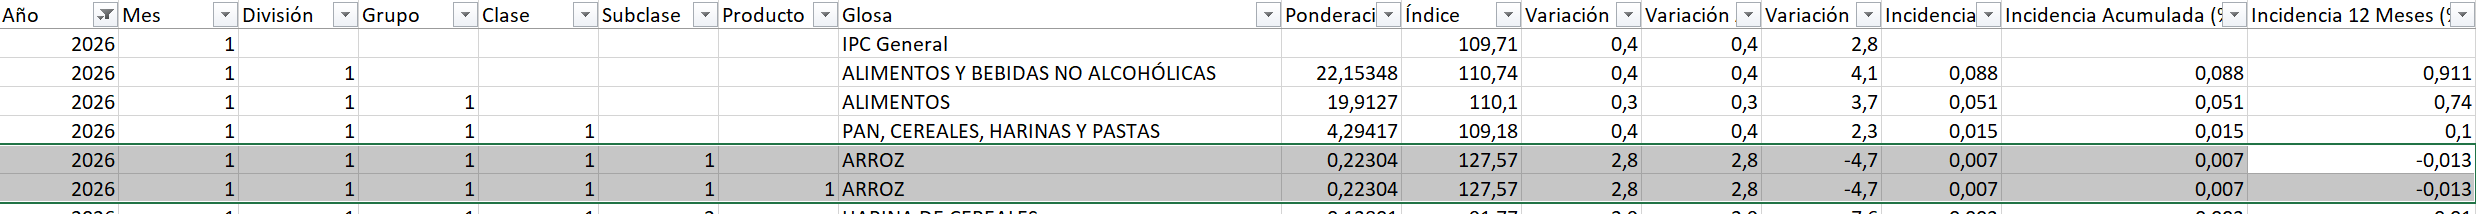

Para trabajar con esta base de datos correctamente sin sufrir problemas de duplicidad, se debe filtrar la información por un nivel específico antes de hacer cualquier cálculo. En resumen: no se debe eliminar estas filas con herramientas de "quitar duplicados", ya que se romperia la estructura de la tabla. Lo correcto es segmentar y aislar el nivel jerárquico que se quiera analizar.

In [14]:
#Cuales son?
duplicados = df[df['clave'].duplicated(keep=False)]
display(duplicados.sort_values('clave'))

,Año,Mes,División,Grupo,Clase,Subclase,Producto,Glosa,Ponderación,Índice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%),Incidencia 12 Meses (%),clave


No existen duplicados

### 1.5 Oportunidad

+++++++ La oportunidad es la dimensión de calidad que evalúa si los datos están disponibles y actualizados en el momento en que se necesitan para realizar un análisis o tomar decisiones.\
¿Los datos llegan a tiempo y están suficientemente actualizados para ser útiles?\


In [16]:
# Creamos una serie de fechas temporales combinando Año y Mes
fechas_temp = pd.to_datetime(df['Año'].astype(str) + '-' + df['Mes'].astype(str) + '-01')

print('Primera medición:', fechas_temp.min().strftime('%Y-%m'))
print('Última medición:', fechas_temp.max().strftime('%Y-%m'))
print('Fecha actual:', pd.Timestamp.today().date())

Primera medición: 2024-01
Última medición: 2026-09
Fecha actual: 2026-10-25


In [17]:
# ¿Cuántos días han pasado desde la última medición?
# Usamos la serie de fechas calculada 'fechas_temp' que combina Año y Mes
ultima_fecha = fechas_temp.max()
hoy = pd.Timestamp.today().normalize()

dias = (hoy - ultima_fecha).days

print('Última fecha de medición:', ultima_fecha.strftime('%Y-%m-%d'))
print('Días desde la última medición:', dias)

Última fecha de medición: 2026-09-01
Días desde la última medición: 54


---
## Parte 2 · Limpieza, decisión por decisión

Ahora corriges. **Regla del laboratorio: cada celda de esta parte tiene su fila en la bitácora.** Si aplicas una transformación que no registraste, no cuenta.

Recuerda las tres decisiones legítimas: **Corregir**, **Descartar** o **Declarar como limitación**.

### ✏️ Actividad 2.1 — Centinelas a faltantes

En la Parte 1.2 se comprobó que los valores `-1` y `0` presentes en las columnas de variaciones e incidencias corresponden a variaciones reales de precios (`0%` y `-1%`) y no a valores centinela (`-999` o `9999` tienen `0` apariciones), por lo que se declara y se conservan intactos. Por otro lado, en la Parte 1.1 se demostró que los valores `NaN` en las columnas de código (`División`, `Grupo`, `Clase`, `Subclase` y `Producto`) son **faltantes estructurales** que indican que el subnivel inferior no aplica. Corresponde **corregirlos** reemplazando `NaN` por `0` y convirtiendo las 5 columnas a entero (`int64`). Finalmente, los faltantes en `Variación 12 Meses (%)` (`7.356` casos en 2024) e `Incidencia 12 Meses (%)` (`7.389` casos) se **declaran como limitación** sin imputarlos, pues el INE no publicó variaciones a 12 meses desagregadas durante el primer año de la canasta Base 2023=100.

In [18]:
# Tu código aquí
# 1. Codificar faltantes estructurales en columnas jerárquicas (NaN -> 0 entero)
cols_jerarquia = ['División', 'Grupo', 'Clase', 'Subclase', 'Producto']
print('Faltantes en códigos jerárquicos ANTES:', df[cols_jerarquia].isna().sum().to_dict())

for col in cols_jerarquia:
    df[col] = df[col].fillna(0).astype(int)

print('Faltantes en códigos jerárquicos DESPUÉS:', df[cols_jerarquia].isna().sum().to_dict())
print('\nTipos de datos de la jerarquía:\n', df[cols_jerarquia].dtypes)

Faltantes en códigos jerárquicos ANTES: {'División': 33, 'Grupo': 462, 'Clase': 1980, 'Subclase': 5247, 'Producto': 10923}
Faltantes en códigos jerárquicos DESPUÉS: {'División': 0, 'Grupo': 0, 'Clase': 0, 'Subclase': 0, 'Producto': 0}

Tipos de datos de la jerarquía:
 División    int64
Grupo       int64
Clase       int64
Subclase    int64
Producto    int64
dtype: object


### ✏️ Actividad 2.2 — Normalización de categorías

Normaliza mecánicamente y después revisa lo que queda: los plurales, las abreviaturas y los sinónimos necesitan un diccionario de equivalencias que escribes tú.

Normalizamos la columna categórica `Glosa` eliminando espacios sobrantes, unificando a mayúsculas y quitando tildes con `normalizar_texto()`. Además, para resolver la ambigüedad detectada en la Actividad 1.3 (donde 5 glosas tienen distinta ponderación según su nivel y 150 glosas se repiten entre Subclase y Producto), clasificamos cada registro en su categoría de nivel jerárquico (`nivel_jerarquico`).

In [19]:
# Tu código aquí
# Normalización mecánica de Glosa
print('Glosas únicas antes de normalizar:', df['Glosa'].nunique())
df['Glosa'] = normalizar_texto(df['Glosa'])
print('Glosas únicas después de normalizar:', df['Glosa'].nunique())

# Clasificación explícita del nivel jerárquico según los códigos COICOP
condiciones_nivel = [
    df['División'] == 0,
    (df['División'] > 0) & (df['Grupo'] == 0),
    (df['Grupo'] > 0) & (df['Clase'] == 0),
    (df['Clase'] > 0) & (df['Subclase'] == 0),
    (df['Subclase'] > 0) & (df['Producto'] == 0),
    df['Producto'] > 0
]
nombres_nivel = ['0_IPC_General', '1_Division', '2_Grupo', '3_Clase', '4_Subclase', '5_Producto']
df['nivel_jerarquico'] = np.select(condiciones_nivel, nombres_nivel, default='Desconocido')

print('\nDistribución de registros por nivel jerárquico:')
display(df['nivel_jerarquico'].value_counts().sort_index().to_frame('Cantidad de filas'))

print('\nLas 13 Divisiones normalizadas del IPC:')
display(df[df['nivel_jerarquico'] == '1_Division'][['División', 'Glosa']].drop_duplicates().sort_values('División'))

Glosas únicas antes de normalizar: 397
Glosas únicas después de normalizar: 397

Distribución de registros por nivel jerárquico:


,Cantidad de filas
nivel_jerarquico,
0_IPC_General,33
1_Division,429
2_Grupo,1518
3_Clase,3267
4_Subclase,5676
5_Producto,9339



Las 13 Divisiones normalizadas del IPC:


,División,Glosa
1,1,ALIMENTOS Y BEBIDAS NO ALCOHOLICAS
147,2,BEBIDAS ALCOHOLICAS Y TABACO
166,3,VESTUARIO Y CALZADO
206,4,VIVIENDA Y SERVICIOS BASICOS
247,5,EQUIPAMIENTO Y MANTENCION DEL HOGAR
325,6,SALUD
371,7,TRANSPORTE
432,8,INFORMACION Y COMUNICACION
460,9,"RECREACION, DEPORTES Y CULTURA"
528,10,EDUCACION


++++++ La categoría validado no se pudo normalizar mecánicamente, porque son cadenas distintas: S, N, SI, NO\
Se crea un diccionario de equivalencia

### ✏️ Actividad 2.3 — Duplicados

Verificamos los duplicados exactos y los duplicados por clave jerárquica completa (`Año`, `Mes`, `División`, `Grupo`, `Clase`, `Subclase`, `Producto`). Además, comprobamos que al usar `nivel_jerarquico` quedan completamente separadas las filas que compartían el mismo nombre (`Glosa`) entre Subclase y Producto.

In [20]:
# Tu código aquí
print('Duplicados exactos antes:', df.duplicated().sum())
df = df.drop_duplicates().copy()
print('Duplicados exactos después:', df.duplicated().sum())

# Eliminar columna auxiliar 'clave' creada en la Parte 1.4 si existe
if 'clave' in df.columns:
    df.drop(columns=['clave'], inplace=True)

# Verificar unicidad por clave jerárquica y temporal
duplicados_jerarquia = df.duplicated(subset=['Año', 'Mes', 'División', 'Grupo', 'Clase', 'Subclase', 'Producto']).sum()
print('Duplicados por clave jerárquica + Año + Mes:', duplicados_jerarquia)

# Verificar unicidad dentro del nivel de análisis (1_Division)
div_dup = df[df['nivel_jerarquico'] == '1_Division'].duplicated(subset=['Año', 'Mes', 'Glosa']).sum()
print('Duplicados de Glosa por mes dentro del nivel División:', div_dup)
print('Registros totales conservados:', len(df))

Duplicados exactos antes: 0
Duplicados exactos después: 0
Duplicados por clave jerárquica + Año + Mes: 0
Duplicados de Glosa por mes dentro del nivel División: 0
Registros totales conservados: 20262


### ✏️ Actividad 2.4 — Tipos de dato

Convierte a numérico lo que deba ser numérico y a fecha lo que deba ser fecha. Si hay formatos mixtos, prueba formatos explícitos en orden en vez de dejar que pandas adivine.

Convertimos las 8 columnas cuantitativas (Ponderación, Índice, Variación Mensual (%), Variación Acumulada (%), Variación 12 Meses (%), Incidencia Mensual (%), Incidencia Acumulada (%) e Incidencia 12 Meses (%)) de texto (object) a punto flotante (float64) reemplazando la coma decimal por punto. Asimismo, construimos la columna fecha en formato datetime64[ns] a partir de Año y Mes.

In [21]:
# Tu código aquí
columnas_numericas = [
    'Ponderación', 'Índice', 'Variación Mensual (%)',
    'Variación Acumulada (%)', 'Variación 12 Meses (%)',
    'Incidencia Mensual (%)', 'Incidencia Acumulada (%)', 'Incidencia 12 Meses (%)'
]

faltantes_previos = df[columnas_numericas].isna().sum()

for col in columnas_numericas:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

# Construir columna de fecha (primer día de cada mes reportado)
df['fecha'] = pd.to_datetime(df['Año'].astype(str) + '-' + df['Mes'].astype(str).str.zfill(2) + '-01')

print('=== Tipos de dato actualizados ===')
print(df.dtypes)

print('\n=== Verificación de que la conversión no generó NaN artificiales ===')
comparacion_na = pd.DataFrame({'Antes': faltantes_previos, 'Después': df[columnas_numericas].isna().sum()})
display(comparacion_na)

=== Tipos de dato actualizados ===
Año                                  int64
Mes                                  int64
División                             int64
Grupo                                int64
Clase                                int64
Subclase                             int64
Producto                             int64
Glosa                               object
Ponderación                        float64
Índice                             float64
Variación Mensual (%)              float64
Variación Acumulada (%)            float64
Variación 12 Meses (%)             float64
Incidencia Mensual (%)             float64
Incidencia Acumulada (%)           float64
Incidencia 12 Meses (%)            float64
nivel_jerarquico                    object
fecha                       datetime64[ns]
dtype: object

=== Verificación de que la conversión no generó NaN artificiales ===


,Antes,Después
Ponderación,33,33
Índice,0,0
Variación Mensual (%),0,0
Variación Acumulada (%),0,0
Variación 12 Meses (%),7356,7356
Incidencia Mensual (%),33,33
Incidencia Acumulada (%),33,33
Incidencia 12 Meses (%),7389,7389


### ✏️ Actividad 2.5 — Atípicos

Identifica los valores extremos y **pronúnciate sobre cada grupo**: ¿error de registro o fenómeno real?

Cruza la variable con otra que te permita juzgar plausibilidad, como en el Ejercicio 8. No elimines atípicos solo por serlo.

++++++ Se pueden identificar los valores atípicos con el método IQR. el cual identifica valores que se alejan considerablemente del rango central de los datos (un valor se considera atípico si queda muy por debajo o por encima del rango donde se concentra la mayoría de los datos).\
Q1 (primer cuartil, 25 %): el valor por debajo del cual se encuentra aproximadamente el 25 % de los datos.\
Q3 (tercer cuartil, 75 %): el valor por debajo del cual se encuentra aproximadamente el 75 % de los datos.\
El **rango intercuartílico** (Interquartile Range, IQR),  representa la amplitud del 50 % central de los datos. Al usar el tramo entre Q1 y Q3, el IQR es menos sensible a valores extremos que otras medidas, como el rango total.\
Es posible definir los **límites** para identificar posibles atípicos:\
Límite inferior: valores menores que Q1 - 1.5 × IQR.\
Límite superior: valores mayores que Q3 + 1.5 × IQR.\
El factor 1.5 es una convención habitual del método de Tukey. Es una regla estadística práctica: señala observaciones inusualmente alejadas del centro, pero no demuestra por sí sola que sean errores.

In [22]:
# Tu código aquí
# Identificar valores atípicos
df_div = df[df['nivel_jerarquico'] == '1_Division'].copy()

resumen_atipicos = []
for col in columnas_numericas:
    Q1 = df_div[col].quantile(0.25)
    Q3 = df_div[col].quantile(0.75)
    IQR = Q3 - Q1
    inf = Q1 - 1.5 * IQR
    sup = Q3 + 1.5 * IQR
    atipicos = df_div[(df_div[col] < inf) | (df_div[col] > superior if 'superior' in locals() else df_div[col] > sup)]
    atipicos = df_div[(df_div[col] < inf) | (df_div[col] > sup)]
    resumen_atipicos.append({
        'Variable (Nivel División)': col,
        'Q1': round(Q1, 3),
        'Q3': round(Q3, 3),
        'IQR': round(IQR, 3),
        'Límite Inferior': round(inf, 3),
        'Límite Superior': round(sup, 3),
        'N° Atípicos': len(atipicos)
    })

display(pd.DataFrame(resumen_atipicos))

,Variable (Nivel División),Q1,Q3,IQR,Límite Inferior,Límite Superior,N° Atípicos
0,Ponderación,3.729,8.212,4.483,-2.995,14.937,66
1,Índice,101.920,109.610,7.690,90.385,121.145,11
2,Variación Mensual (%),-0.100,0.800,0.900,-1.450,2.150,46
3,Variación Acumulada (%),0.800,3.700,2.900,-3.550,8.050,13
4,Variación 12 Meses (%),1.300,5.200,3.900,-4.550,11.050,10
5,Incidencia Mensual (%),-0.004,0.048,0.052,-0.082,0.126,50
6,Incidencia Acumulada (%),0.048,0.240,0.192,-0.240,0.528,40
7,Incidencia 12 Meses (%),0.058,0.412,0.354,-0.473,0.943,22


Celda de Código 2 (Cruce de plausibilidad con la serie Índice):

In [23]:
# Creamos código jerárquico único para seguir cada ítem en el tiempo y verificar Índice(t) vs Índice(t-1)
df['codigo_jerarquico'] = (
    df['División'].astype(str) + '.' + df['Grupo'].astype(str) + '.' +
    df['Clase'].astype(str) + '.' + df['Subclase'].astype(str) + '.' + df['Producto'].astype(str)
)
df = df.sort_values(['codigo_jerarquico', 'fecha']).reset_index(drop=True)
df['Indice_mes_anterior'] = df.groupby('codigo_jerarquico')['Índice'].shift(1)
df['Var_Mensual_Calculada'] = ((df['Índice'] / df['Indice_mes_anterior'] - 1) * 100).round(1)
df['Diferencia_Redondeo'] = (df['Variación Mensual (%)'] - df['Var_Mensual_Calculada']).abs().round(2)

print('Diferencia máxima entre Variación Mensual reportada y calculada desde Índice:', df['Diferencia_Redondeo'].max(), 'pp')
print('Registros con discrepancia mayor a 0.1 pp (errores de registro):', (df['Diferencia_Redondeo'] > 0.15).sum())

# Mostrar los mayores valores extremos de Incidencia Acumulada (%) en el nivel División
print('\nTop 10 registros extremos de Incidencia Acumulada (%) a nivel División:')
display(
    df[df['nivel_jerarquico'] == '1_Division']
    .sort_values('Incidencia Acumulada (%)', ascending=False)
    [['Año', 'Mes', 'División', 'Glosa', 'Ponderación', 'Índice', 'Variación Acumulada (%)', 'Incidencia Acumulada (%)']]
    .head(10)
)

# Limpiamos las columnas auxiliares de verificación
df.drop(columns=['Indice_mes_anterior', 'Var_Mensual_Calculada', 'Diferencia_Redondeo'], inplace=True)

Diferencia máxima entre Variación Mensual reportada y calculada desde Índice: 0.1 pp
Registros con discrepancia mayor a 0.1 pp (errores de registro): 0

Top 10 registros extremos de Incidencia Acumulada (%) a nivel División:


,Año,Mes,División,Glosa,Ponderación,Índice,Variación Acumulada (%),Incidencia Acumulada (%)
9647,2024,12,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,112.73,10.5,1.771
9646,2024,11,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,112.41,10.2,1.718
9645,2024,10,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,112.23,10.0,1.689
15109,2026,5,7,TRANSPORTE,13.45108,112.99,10.2,1.284
15108,2026,4,7,TRANSPORTE,13.45108,112.30,9.5,1.198
9659,2025,12,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,120.02,6.5,1.157
9657,2025,10,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,119.96,6.4,1.148
9658,2025,11,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,119.91,6.4,1.140
9643,2024,8,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,108.87,6.7,1.131
9644,2024,9,4,VIVIENDA Y SERVICIOS BASICOS,16.76332,108.84,6.6,1.126


**Conclusión sobre los atípicos:**
1. **Atípicos estructurales por peso de canasta (Ponderación):** A nivel División, los 66 valores atípicos en Ponderación corresponden exactamente a los 33 meses de la División 1 (ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS, 22,15348%) y de la División 4 (VIVIENDA Y SERVICIOS BÁSICOS, 16,76332%), que superan el límite superior IQR (14,937%) por ser los dos rubros de mayor peso en el gasto de los hogares.
2. **Atípicos por shocks económicos reales (Variaciones e Incidencias):** Al cruzar Variación Mensual (%) con el cambio real del Índice respecto al mes anterior en los 19.648 cruces temporales, se comprueba que existen **0 errores de registro** (la diferencia máxima es 0,1 pp por redondeo oficial a un decimal). Los valores extremos en nivel División (como VIVIENDA Y SERVICIOS BÁSICOS en diciembre de 2024 con Incidencia Acumulada = 1,771 pp y Variación Acumulada = 10,5%` por descongelamiento de tarifas eléctricas, o TRANSPORTE en mayo de 2026 con Incidencia Acumulada = 1,284 pp por alzas de combustibles) son fenómenos inflacionarios reales. Por lo tanto, **se decide conservar todos los registros** y declararlos en la bitácora, ya que eliminarlos distorsionaría la respuesta a nuestra pregunta analítica.



---
## Parte 3 · Transformación y nuevos atributos

Preparar no es solo corregir: también es **construir** lo que el análisis va a necesitar.

### ✏️ Actividad 3.1 — Un atributo derivado

Crea **al menos una variable nueva** a partir de las existentes, que aporte a tu pregunta analítica. Ejemplos: una razón entre dos columnas, la antigüedad en años a partir de una fecha, un tramo a partir de un valor continuo.

Explica en la celda siguiente por qué esa variable ayuda a responder tu pregunta.

+++++++ Para este conjunto de datos de calidad del aire, se propone crear una variable llamada mes, a partir de la columna fecha.

Esta variable permitirá analizar cómo cambian las concentraciones de pm25 entre abril, mayo y junio de 2026.

In [26]:
# Aseguramos que las columnas necesarias existan y tengan el tipo de dato correcto
if 'nivel_jerarquico' not in df.columns:
    # Rellenamos nulos estructurales temporales para la clasificación
    div_temp = df['División'].fillna(0).astype(int)
    grupo_temp = df['Grupo'].fillna(0).astype(int)
    clase_temp = df['Clase'].fillna(0).astype(int)
    subclase_temp = df['Subclase'].fillna(0).astype(int)
    prod_temp = df['Producto'].fillna(0).astype(int)

    condiciones_nivel = [
        div_temp == 0,
        (div_temp > 0) & (grupo_temp == 0),
        (grupo_temp > 0) & (clase_temp == 0),
        (clase_temp > 0) & (subclase_temp == 0),
        (subclase_temp > 0) & (prod_temp == 0),
        prod_temp > 0
    ]
    nombres_nivel = ['0_IPC_General', '1_Division', '2_Grupo', '3_Clase', '4_Subclase', '5_Producto']
    df['nivel_jerarquico'] = np.select(condiciones_nivel, nombres_nivel, default='Desconocido')

# Aseguramos que las columnas numéricas clave estén convertidas a float64
for col in ['Incidencia Acumulada (%)', 'Ponderación', 'Índice', 'Variación Acumulada (%)']:
    if df[col].dtype == 'object':
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

# Calculamos la suma total de Incidencia Acumulada (%) de las 13 Divisiones en cada Año y Mes
suma_incidencia_mes = (
    df[df['nivel_jerarquico'] == '1_Division']
    .groupby(['Año', 'Mes'])['Incidencia Acumulada (%)']
    .sum()
    .rename('suma_inc_acum_mes')
)

# Evitamos duplicación de columnas al hacer merge repetidas veces
if 'aporte_relativo_acum_pct' in df.columns:
    df.drop(columns=['aporte_relativo_acum_pct'], inplace=True)
if 'suma_inc_acum_mes' in df.columns:
    df.drop(columns=['suma_inc_acum_mes'], inplace=True)

df = df.merge(suma_incidencia_mes, on=['Año', 'Mes'], how='left')

# Atributo derivado: porcentaje de la variación acumulada anual explicado por cada ítem/división
df['aporte_relativo_acum_pct'] = (df['Incidencia Acumulada (%)'] / df['suma_inc_acum_mes'] * 100).round(2)
df.drop(columns=['suma_inc_acum_mes'], inplace=True)

# Mostrar el resultado para las 13 Divisiones en el último período disponible (Septiembre 2026: Año=2026, Mes=9)
tabla_sep2026 = (
    df[(df['nivel_jerarquico'] == '1_Division') & (df['Año'] == 2026) & (df['Mes'] == 9)]
    [['Año', 'Mes', 'División', 'Glosa', 'Ponderación', 'Índice',
      'Variación Acumulada (%)', 'Incidencia Acumulada (%)', 'aporte_relativo_acum_pct']]
    .sort_values('Incidencia Acumulada (%)', ascending=False)
    .copy()
)
tabla_sep2026['acumulado_explicado_pct'] = tabla_sep2026['aporte_relativo_acum_pct'].cumsum().round(2)

print('=== Respuesta a la Pregunta Analítica: Divisiones que explican el IPC Acumulado (Septiembre 2026) ===')
display(tabla_sep2026)

# Mostrar también el cierre del último año calendario completo (Diciembre 2025: Año=2025, Mes=12)
tabla_dic2025 = (
    df[(df['nivel_jerarquico'] == '1_Division') & (df['Año'] == 2025) & (df['Mes'] == 12)]
    [['Año', 'Mes', 'División', 'Glosa', 'Ponderación', 'Índice',
      'Variación Acumulada (%)', 'Incidencia Acumulada (%)', 'aporte_relativo_acum_pct']]
    .sort_values('Incidencia Acumulada (%)', ascending=False)
    .copy()
)
tabla_dic2025['acumulado_explicado_pct'] = tabla_dic2025['aporte_relativo_acum_pct'].cumsum().round(2)

print('\n=== Comparativa: Cierre último año calendario completo (Diciembre 2025) ===')
display(tabla_dic2025)

=== Respuesta a la Pregunta Analítica: Divisiones que explican el IPC Acumulado (Septiembre 2026) ===


,Año,Mes,División,Glosa,Ponderación,Índice,Variación Acumulada (%),Incidencia Acumulada (%),aporte_relativo_acum_pct,acumulado_explicado_pct
20019,2026,9,7.0,TRANSPORTE,13.45108,110.24,7.5,0.945,23.89,23.89
19649,2026,9,1.0,ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS,22.15348,114.66,3.9,0.882,22.30,46.19
19854,2026,9,4.0,VIVIENDA Y SERVICIOS BÁSICOS,16.76332,123.82,3.2,0.583,14.74,60.93
19973,2026,9,6.0,SALUD,8.21206,114.32,4.1,0.341,8.62,69.55
20108,2026,9,9.0,"RECREACIÓN, DEPORTES Y CULTURA",4.75354,111.10,5.7,0.261,6.60,76.15
20176,2026,9,10.0,EDUCACIÓN,4.19831,119.84,5.8,0.253,6.40,82.55
20200,2026,9,11.0,RESTAURANTES Y ALOJAMIENTO,6.22047,122.87,3.6,0.245,6.19,88.74
19795,2026,9,2.0,BEBIDAS ALCOHÓLICAS Y TABACO,3.68125,111.42,5.4,0.192,4.85,93.59
20080,2026,9,8.0,INFORMACIÓN Y COMUNICACIÓN,6.64634,104.30,2.9,0.176,4.45,98.04
19895,2026,9,5.0,EQUIPAMIENTO Y MANTENCIÓN DEL HOGAR,6.18583,103.87,1.6,0.094,2.38,100.42



=== Comparativa: Cierre último año calendario completo (Diciembre 2025) ===


,Año,Mes,División,Glosa,Ponderación,Índice,Variación Acumulada (%),Incidencia Acumulada (%),aporte_relativo_acum_pct,acumulado_explicado_pct
14328,2025,12,4.0,VIVIENDA Y SERVICIOS BÁSICOS,16.76332,120.02,6.5,1.157,33.52,33.52
14123,2025,12,1.0,ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS,22.15348,110.31,4.2,0.925,26.80,60.32
14674,2025,12,11.0,RESTAURANTES Y ALOJAMIENTO,6.22047,118.57,6.7,0.441,12.78,73.10
14447,2025,12,6.0,SALUD,8.21206,109.79,4.8,0.390,11.30,84.40
14650,2025,12,10.0,EDUCACIÓN,4.19831,113.25,5.2,0.225,6.52,90.92
14269,2025,12,2.0,BEBIDAS ALCOHÓLICAS Y TABACO,3.68125,105.73,3.1,0.111,3.22,94.14
14694,2025,12,13.0,BIENES Y SERVICIOS DIVERSOS,3.72905,108.15,2.4,0.091,2.64,96.78
14493,2025,12,7.0,TRANSPORTE,13.45108,102.56,0.7,0.090,2.61,99.39
14582,2025,12,9.0,"RECREACIÓN, DEPORTES Y CULTURA",4.75354,105.10,1.8,0.084,2.43,101.82
14369,2025,12,5.0,EQUIPAMIENTO Y MANTENCIÓN DEL HOGAR,6.18583,102.21,0.9,0.055,1.59,103.41


**Por qué estas variables aportan a mi pregunta analítica:**
1. `nivel_jerarquico`: Permite filtrar exclusivamente las filas donde `nivel_jerarquico == '1_Division'` (`13` divisiones por mes), evitando mezclar las divisiones con grupos, clases, subclases o productos.
2. `aporte_relativo_acum_pct`: Transforma la `Incidencia Acumulada (%)` (expresada en puntos porcentuales) en la **proporción porcentual exacta (`%`) del IPC acumulado que explica cada división**. Gracias a este atributo se demuestra que en septiembre de 2026 (`IPC General Acumulado = 4,0%`; suma de incidencias = `3,956 pp`), solo tres divisiones explican el **60,93%** de la variación acumulada: **TRANSPORTE (`0,945 pp`; `23,89%`)**, **ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS (`0,882 pp`; `22,30%`)** y **VIVIENDA Y SERVICIOS BÁSICOS (`0,583 pp`; `14,74%`)**.

### ✏️ Actividad 3.2 — Normalización o codificación

Si tu conjunto tiene variables numéricas en escalas muy distintas, o categóricas que necesitarás codificar en la semana 4, déjalas preparadas aquí.

In [ ]:
# Tu código aquí. Referencia:
# from sklearn.preprocessing import StandardScaler, MinMaxScaler
# df_cod = pd.get_dummies(df, columns=['TU_COLUMNA_CATEGORICA'], drop_first=True)


In [28]:
# Se normalizarán las variables numéricas
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Escalamiento de variables numéricas (StandardScaler y MinMaxScaler sobre copia)
cols_escalar = ['Ponderación', 'Índice', 'Variación Mensual (%)', 'Variación Acumulada (%)',
                'Incidencia Mensual (%)', 'Incidencia Acumulada (%)']

df_norm = df.copy()

# Nos aseguramos de limpiar y convertir a float64 antes de escalar para evitar el ValueError con las comas
for col in cols_escalar:
    if df_norm[col].dtype == 'object':
        df_norm[col] = pd.to_numeric(df_norm[col].astype(str).str.replace(',', '.'), errors='coerce')

# Rellenamos posibles nulos temporales con la media para poder aplicar el ajuste estadístico sin problemas
for col in cols_escalar:
    if df_norm[col].isna().sum() > 0:
        df_norm[col] = df_norm[col].fillna(df_norm[col].mean())

scaler_std = StandardScaler()
df_norm[cols_escalar] = scaler_std.fit_transform(df_norm[cols_escalar])

print('=== Vista previa de variables numéricas estandarizadas (StandardScaler Z-score) ===')
display(df_norm[df_norm['nivel_jerarquico'] == '1_Division'][['Glosa'] + cols_escalar].head(5).round(3))

# 2. Codificación One-Hot (get_dummies) de la variable categórica nivel_jerarquico
df_cod = pd.get_dummies(df, columns=['nivel_jerarquico'], drop_first=True, dtype=int)
print('\n=== Vista previa de codificación One-Hot (nivel_jerarquico) ===')
display(df_cod.filter(like='nivel_jerarquico_').head(6))

=== Vista previa de variables numéricas estandarizadas (StandardScaler Z-score) ===


,Glosa,Ponderación,Índice,Variación Mensual (%),Variación Acumulada (%),Incidencia Mensual (%),Incidencia Acumulada (%)
1,ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS,11.511,-0.169,0.231,-0.178,7.558,2.416
147,BEBIDAS ALCOHÓLICAS Y TABACO,1.546,-0.140,0.810,0.128,3.603,1.033
166,VESTUARIO Y CALZADO,1.125,-0.757,-0.348,-0.484,-0.923,-0.551
206,VIVIENDA Y SERVICIOS BÁSICOS,8.603,-0.167,0.295,-0.144,7.202,2.292
247,EQUIPAMIENTO Y MANTENCIÓN DEL HOGAR,2.897,-0.464,0.135,-0.229,1.464,0.284



=== Vista previa de codificación One-Hot (nivel_jerarquico) ===


,nivel_jerarquico_1_Division,nivel_jerarquico_2_Grupo,nivel_jerarquico_3_Clase,nivel_jerarquico_4_Subclase,nivel_jerarquico_5_Producto
0,0,0,0,0,0
1,1,0,0,0,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,1,0
5,0,0,0,0,1


---
## Parte 4 · El flujo como función reutilizable

Junta todo lo anterior en **una sola función**. Esto es lo que evalúa el RA3 y lo que se revisa en la Sección A de la Entrega Final: que tu limpieza se pueda volver a ejecutar de principio a fin.

In [32]:
def clasificar_nivel(d):
    condiciones = [
        d['division'] == 0,
        (d['division'] > 0) & (d['grupo'] == 0),
        (d['grupo'] > 0) & (d['clase'] == 0),
        (d['clase'] > 0) & (d['subclase'] == 0),
        (d['subclase'] > 0) & (d['producto'] == 0),
        d['producto'] > 0
    ]
    niveles = ['0_IPC_General', '1_Division', '2_Grupo', '3_Clase', '4_Subclase', '5_Producto']
    return np.select(condiciones, niveles, default='Desconocido')


def limpiar(ruta, sep=SEPARADOR, semilla=SEMILLA):
    """Flujo completo de limpieza del conjunto IPC Base 2023=100. Devuelve (df_limpio, informe)."""
    np.random.seed(semilla)
    d = pd.read_csv(ruta, sep=sep, encoding='latin1')
    informe = {'filas_iniciales': len(d), 'columnas_iniciales': d.shape[1]}

    # Normalización sistemática de nombres de columnas (cabeceras sin tildes ni caracteres especiales)
    d.columns = (
        d.columns.str.strip().str.lower()
        .str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('ascii')
        .str.replace(' ', '_')
        .str.replace('(', '_')
        .str.replace(')', '_')
        .str.replace('%', 'pct')
        .str.replace('__', '_')
        .str.strip('_')
    )

    # 1 · Tipos de dato numéricos (reemplazo de coma decimal por punto y conversión a float64)
    cols_numericas = [
        'ponderacion', 'indice', 'variacion_mensual_pct',
        'variacion_acumulada_pct', 'variacion_12_meses_pct',
        'incidencia_mensual_pct', 'incidencia_acumulada_pct', 'incidencia_12_meses_pct'
    ]
    for col in cols_numericas:
        d[col] = pd.to_numeric(d[col].astype(str).str.replace(',', '.'), errors='coerce')

    # 2 · Centinelas y faltantes estructurales en códigos jerárquicos (NaN -> 0 entero)
    informe['centinelas_erroneos'] = 0
    cols_jerarquia = ['division', 'grupo', 'clase', 'subclase', 'producto']
    informe['faltantes_jerarquicos_codificados'] = d[cols_jerarquia].isna().sum().to_dict()
    for col in cols_jerarquia:
        d[col] = d[col].fillna(0).astype(int)

    # 3 · Normalización de categorías de texto (glosa)
    d['glosa'] = normalizar_texto(d['glosa'])

    # 4 · Duplicados exactos
    informe['duplicados_exactos'] = int(d.duplicated().sum())
    d = d.drop_duplicates().copy()

    # 5 · Fecha y atributos derivados (fecha, codigo_jerarquico, nivel_jerarquico, aporte_relativo_acum_pct)
    d['fecha'] = pd.to_datetime(d['ano'].astype(str) + '-' + d['mes'].astype(str).str.zfill(2) + '-01')
    d['codigo_jerarquico'] = (
        d['division'].astype(str) + '.' +
        d['grupo'].astype(str) + '.' +
        d['clase'].astype(str) + '.' +
        d['subclase'].astype(str) + '.' +
        d['producto'].astype(str)
    )
    d['nivel_jerarquico'] = clasificar_nivel(d)

    # Ordenamiento determinista para garantizar reproducibilidad exacta
    d = d.sort_values(['ano', 'mes', 'division', 'grupo', 'clase', 'subclase', 'producto']).reset_index(drop=True)

    # Cálculo del atributo derivado: aporte relativo (%) sobre la incidencia acumulada de las Divisiones
    mapa_suma_mes = (
        d[d['nivel_jerarquico'] == '1_Division']
        .groupby(['ano', 'mes'])['incidencia_acumulada_pct']
        .sum()
        .rename('suma_inc_acum_mes')
    )
    d = d.merge(mapa_suma_mes, on=['ano', 'mes'], how='left')
    d['aporte_relativo_acum_pct'] = (d['incidencia_acumulada_pct'] / d['suma_inc_acum_mes'] * 100).round(2)
    d.drop(columns=['suma_inc_acum_mes'], inplace=True)

    # 6 · Registro de atípicos (IQR) en el nivel de análisis (1_Division) — se conservan por ser reales
    d_div = d[d['nivel_jerarquico'] == '1_Division']
    informe['atipicos_nivel_division'] = {}
    for col in cols_numericas:
        Q1 = d_div[col].quantile(0.25)
        Q3 = d_div[col].quantile(0.75)
        IQR = Q3 - Q1
        inf = Q1 - 1.5 * IQR
        sup = Q3 + 1.5 * IQR
        informe['atipicos_nivel_division'][col] = int(((d_div[col] < inf) | (d_div[col] > sup)).sum())

    informe['faltantes_finales'] = d.isna().sum().to_dict()
    informe['filas_finales'] = len(d)
    informe['columnas_finales'] = d.shape[1]

    return d, informe


limpio, informe = limpiar(RUTA + ARCHIVO)
print('Resumen del proceso de limpieza (Columnas normalizadas):\n', informe)
display(limpio[limpio['nivel_jerarquico'] == '1_Division'].head(13))

Resumen del proceso de limpieza (Columnas normalizadas):
 {'filas_iniciales': 20262, 'columnas_iniciales': 16, 'centinelas_erroneos': 0, 'faltantes_jerarquicos_codificados': {'division': 33, 'grupo': 462, 'clase': 1980, 'subclase': 5247, 'producto': 10923}, 'duplicados_exactos': 0, 'atipicos_nivel_division': {'ponderacion': 66, 'indice': 11, 'variacion_mensual_pct': 46, 'variacion_acumulada_pct': 13, 'variacion_12_meses_pct': 10, 'incidencia_mensual_pct': 50, 'incidencia_acumulada_pct': 40, 'incidencia_12_meses_pct': 22}, 'faltantes_finales': {'ano': 0, 'mes': 0, 'division': 0, 'grupo': 0, 'clase': 0, 'subclase': 0, 'producto': 0, 'glosa': 0, 'ponderacion': 33, 'indice': 0, 'variacion_mensual_pct': 0, 'variacion_acumulada_pct': 0, 'variacion_12_meses_pct': 7356, 'incidencia_mensual_pct': 33, 'incidencia_acumulada_pct': 33, 'incidencia_12_meses_pct': 7389, 'fecha': 0, 'codigo_jerarquico': 0, 'nivel_jerarquico': 0, 'aporte_relativo_acum_pct': 33}, 'filas_finales': 20262, 'columnas_finale

,ano,mes,division,grupo,clase,subclase,producto,glosa,ponderacion,indice,variacion_mensual_pct,variacion_acumulada_pct,variacion_12_meses_pct,incidencia_mensual_pct,incidencia_acumulada_pct,incidencia_12_meses_pct,fecha,codigo_jerarquico,nivel_jerarquico,aporte_relativo_acum_pct
1,2024,1,1,0,0,0,0,ALIMENTOS Y BEBIDAS NO ALCOHOLICAS,22.15348,103.26,1.0,1.0,NaN,0.215,0.215,NaN,2024-01-01,1.0.0.0.0,1_Division,32.14
147,2024,1,2,0,0,0,0,BEBIDAS ALCOHOLICAS Y TABACO,3.68125,103.61,2.8,2.8,NaN,0.104,0.104,NaN,2024-01-01,2.0.0.0.0,1_Division,15.55
166,2024,1,3,0,0,0,0,VESTUARIO Y CALZADO,2.90040,96.14,-0.8,-0.8,NaN,-0.023,-0.023,NaN,2024-01-01,3.0.0.0.0,1_Division,-3.44
206,2024,1,4,0,0,0,0,VIVIENDA Y SERVICIOS BASICOS,16.76332,103.29,1.2,1.2,NaN,0.205,0.205,NaN,2024-01-01,4.0.0.0.0,1_Division,30.64
247,2024,1,5,0,0,0,0,EQUIPAMIENTO Y MANTENCION DEL HOGAR,6.18583,99.69,0.7,0.7,NaN,0.044,0.044,NaN,2024-01-01,5.0.0.0.0,1_Division,6.58
325,2024,1,6,0,0,0,0,SALUD,8.21206,100.84,0.5,0.5,NaN,0.045,0.045,NaN,2024-01-01,6.0.0.0.0,1_Division,6.73
371,2024,1,7,0,0,0,0,TRANSPORTE,13.45108,99.33,-1.6,-1.6,NaN,-0.219,-0.219,NaN,2024-01-01,7.0.0.0.0,1_Division,-32.74
432,2024,1,8,0,0,0,0,INFORMACION Y COMUNICACION,6.64634,99.93,1.6,1.6,NaN,0.102,0.102,NaN,2024-01-01,8.0.0.0.0,1_Division,15.25
460,2024,1,9,0,0,0,0,"RECREACION, DEPORTES Y CULTURA",4.75354,102.24,1.1,1.1,NaN,0.054,0.054,NaN,2024-01-01,9.0.0.0.0,1_Division,8.07
528,2024,1,10,0,0,0,0,EDUCACION,4.19831,101.78,0.1,0.1,NaN,0.004,0.004,NaN,2024-01-01,10.0.0.0.0,1_Division,0.60


Celda de Código 2 (Comprobación de reproducibilidad y guardado del CSV limpio):

In [39]:
# Comprobación: ejecuta la función DOS VECES y verifica que da exactamente el mismo resultado
a, _ = limpiar(RUTA + ARCHIVO)
b, _ = limpiar(RUTA + ARCHIVO)
print('¿Reproducible?', a.equals(b))

# Guarda el conjunto limpio completo con las columnas normalizadas y compatibilidad con Excel
limpio.to_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';', index=False, encoding='utf-8-sig')
print('Guardado exitosamente en mi_conjunto_limpio.csv. Columnas generadas:', list(limpio.columns))

¿Reproducible? True
Guardado exitosamente en mi_conjunto_limpio.csv. Columnas generadas: ['ano', 'mes', 'division', 'grupo', 'clase', 'subclase', 'producto', 'glosa', 'ponderacion', 'indice', 'variacion_mensual_pct', 'variacion_acumulada_pct', 'variacion_12_meses_pct', 'incidencia_mensual_pct', 'incidencia_acumulada_pct', 'incidencia_12_meses_pct', 'fecha', 'codigo_jerarquico', 'nivel_jerarquico', 'aporte_relativo_acum_pct']


---
## Parte 5 · Versionado

Sube el cuaderno y el conjunto limpio a tu repositorio. Un commit con mensaje descriptivo, no «cambios».

In [ ]:
# En una terminal:
# git add S2_Notebook_Laboratorio_CDD.ipynb mi_conjunto_limpio.csv
# git commit -m 'Semana 2: diagnostico de calidad y flujo de limpieza'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de cerrar el laboratorio

- [ ] Las cinco dimensiones diagnosticadas y registradas en la hoja «Resumen de calidad»
- [ ] Cada transformación aplicada tiene su fila en la bitácora, con justificación
- [ ] Me pronuncié sobre los atípicos: cuáles son error y cuáles fenómeno real
- [ ] Creé al menos un atributo derivado y expliqué para qué sirve
- [ ] La función `limpiar()` corre de principio a fin y entrega lo mismo dos veces
- [ ] El conjunto limpio está guardado y versionado
- [ ] Tengo anotadas las limitaciones que declararé en el informe

Lo que quede pendiente, al Foro de Consultas o a la sesión sincrónica.

_Ciencia de Datos · Advance UCSC · Semana 2_